<a href="https://colab.research.google.com/github/yabsra-g/ml/blob/main/cifar_resnet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
drive_cifar = '/content/drive/MyDrive/ml/cifar10_data.npz'
data = np.load(drive_cifar)

x_train = data['x_train']
y_train = data['y_train']
x_test = data['x_test']
y_test = data['y_test']

In [ ]:
y_train = y_train.flatten()
y_test = y_test.flatten()

In [ ]:
inputs = layers.Input(shape=(32, 32, 3))
x = layers.UpSampling2D(size=(2, 2))(inputs)
x = layers.Lambda(preprocess_input)(x)

base_model = ResNet50(weights='imagenet',include_top=False, input_shape=(64, 64, 3))
base_model.trainable = False

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(10, activation='softmax')(x)

model = models.Model(inputs=inputs, outputs=outputs)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [ ]:
drive_dir = '/content/drive/MyDrive/ml'
checkpoint_path = os.path.join(drive_dir, 'resnet50_cifar10_best.keras')

checkpoint_path = os.path.join(drive_dir, 'resnet50_cifar10_best.keras')
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path, monitor='val_accuracy', save_best_only=True)
]

In [ ]:
history = model.fit(x_train, y_train, validation_data=(x_test, y_test), epochs=10, batch_size=128, callbacks=callbacks, verbose=1)

Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 47s 85ms/step - accuracy: 0.6992 - loss: 0.9123 - val_accuracy: 0.7666 - val_loss: 0.6642
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - accuracy: 0.7689 - loss: 0.6678 - val_accuracy: 0.7835 - val_loss: 0.6150
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - accuracy: 0.7928 - loss: 0.5947 - val_accuracy: 0.7906 - val_loss: 0.6023
Epoch 4/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 21s 43ms/step - accuracy: 0.8084 - loss: 0.5421 - val_accuracy: 0.7969 - val_loss: 0.6004
Epoch 5/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 15s 39ms/step - accuracy: 0.8204 - loss: 0.5012 - val_accuracy: 0.7963 - val_loss: 0.6044
Epoch 6/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 17s 43ms/step - accuracy: 0.8373 - loss: 0.4596 - val_accuracy: 0.7979 - val_loss: 0.5975
Epoch 7/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 17s 43ms/step - accuracy: 0.8460 - loss: 0.4290 - val_accuracy: 0.7987 - val_loss: 0.6030
Epoch 8/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 17s 44ms/step - accuracy: 0.8531 - loss: 0.4033 - 

In [ ]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nFinal Test Accuracy: {test_acc * 100:.2f}%")


Final Test Accuracy: 80.26%


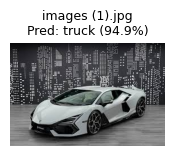

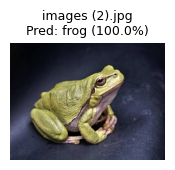

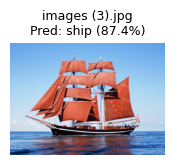

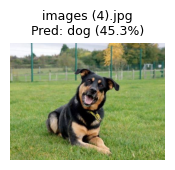

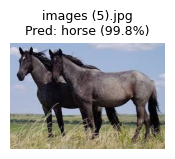

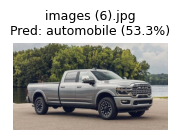

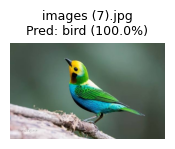

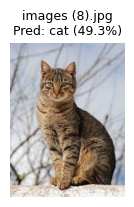

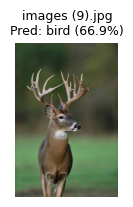

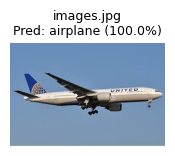

In [ ]:
class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
folder_path = '/content/drive/MyDrive/ml/objects'
valid_exts = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

for filename in sorted(os.listdir(folder_path)):
    if not filename.lower().endswith(valid_exts):
        continue

    file_path = os.path.join(folder_path, filename)
    img_bgr = cv2.imread(file_path)
    if img_bgr is None:
        continue

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, (32, 32))
    img_batch = np.expand_dims(img_resized.astype('float32'), axis=0)

    pred = model.predict(img_batch, verbose=0)
    pred_idx = np.argmax(pred)
    confidence = pred[0][pred_idx] * 100

    plt.figure(figsize=(2, 2))
    plt.imshow(img_rgb)
    plt.title(f"{filename}\nPred: {class_names[pred_idx]} ({confidence:.1f}%)", fontsize=9)
    plt.axis('off')
    plt.show()